# 03 — Does the 24 h state predict the 5 d state?

Each passage well is one culture sampled twice: at 24 h (before the first dilution) and
at 5 d (after daily dilution). So for every member of every well there is a pair of
abundances, and the question is how much of the 5 d composition is already written at
24 h.

**Coverage is the first question, not an afterthought.** The two trajectories are
mirror images in depth:

| culture plate | 24 h (barcode plate) | 5 d (barcode plate) |
|---|---|---|
| 5 | plate 5 — deep (~2000 reads/well) | plate 9 — shallow (~100) |
| 6 | plate 6 — shallow (~100) | plate 10 — deep (~2300) |

So one end of every pair is measured at ~100 reads. Section 1 asks what that costs;
every score below is shown next to the score a *perfect* prediction would get from
sampling noise alone.

Models (`community_qc.prediction`), all in within-well log-ratio space and all fitted
**leave-community-out** (every replicate of a community, on both plates, held out
together):

| model | prediction for the 5 d composition | what it tests |
|---|---|---|
| persistence | = the 24 h composition | nothing changes |
| strain | ∝ exp(β_strain) | only *who* is in the well matters |
| 24h + strain | ∝ exp(γ·x₂₄ₕ + β_strain) | 24 h abundance, discounted, plus strain identity |
| sister 24h + strain | same model fed the *other replicates'* 24 h | does the well's *own* 24 h deviation carry forward? |
| sister ceiling | = the other replicates' observed 5 d | how reproducible 5 d is at all (not a 24 h model) |

Reads: `outputs/q04_member_table.csv` (member reads only; foreign and unexplained reads
are notebook 01's business).

In [1]:
import sys, json
from pathlib import Path
QC_DIR = Path("/home/rl/scripts/karl/sequencing_experiments/community_assembly_experiments/20261026/02_qc")
sys.path.insert(0, str(QC_DIR))
import config                                   # paths; puts the shared libraries on sys.path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from community_qc import plots as P, composition as comp, io as cio
P.setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
OUT, FIG = config.OUT, config.FIG
TH = json.load(open(OUT / "q02_thresholds.json"))
lay = cio.load_layout(config.LAYOUT_CSV)
def savefig(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

from community_qc import prediction as pred
mt = pd.read_csv(OUT / "q04_member_table.csv")
ws = pd.read_csv(OUT / "q04_well_summary.csv")
pm = pred.paired_members(mt, "24h", "5d")
print(f"{pm[['culture_plate','well']].drop_duplicates().shape[0]} passage wells with both time points in the layout")

612 passage wells with both time points in the layout


## Summary (numbers reproduced below)

- **Coverage is enough for the main question, not for the rare tail.** 180 + 179
  paired wells have ≥ 30 member reads at both time points. One side of every pair sits
  at ~100 reads, so the dominant members and their rough shares are measured, but
  members under ~5% are not.
- **Only about a third of the 24 h state carries forward.** In log-ratio space, 5 d ≈
  0.33 × 24 h + a strain effect (γ = 0.33, stable across folds). That is close to the 0.31
  of a starting ratio that survived to the endpoint in 20260907's inoculum titration.
  Members ≥ 1% fall from a median 10 to 6 in the largest communities; 37% of members
  present at 24 h are below 1% at 5 d, and the 24 h dominant is still dominant in ~60% of wells.
- **24 h + strain identity is the best 24 h model, but far from the ceiling.** Median
  BC to the observed 5 d state is 0.30 / 0.22 (culture plates 5 / 6), vs 0.32 / 0.31 for
  "nothing changes" and 0.33 / 0.24 for strain identity alone. Survival of a member to 5 d
  is predicted with AUC 0.89 (persistence 0.84).
- **The 5 d state is highly reproducible: sister replicates predict it at BC 0.10–0.11.**
  So 5 d is largely determined by the community, and what 24 h + additive strain
  effects miss is community-specific, i.e. interactions.
- **A well's own 24 h deviations do not carry forward.** The sister replicates' 24 h
  predicts a well's 5 d exactly as well as its own 24 h (median BC 0.254 vs 0.255,
  p = 0.89). Early stochastic differences are erased by 5 d.

## 1. Coverage: is there enough to do this?

culture_plate,5,6
min_member_reads_both,,
10,226,233
30,180,179
100,92,52
300,14,11


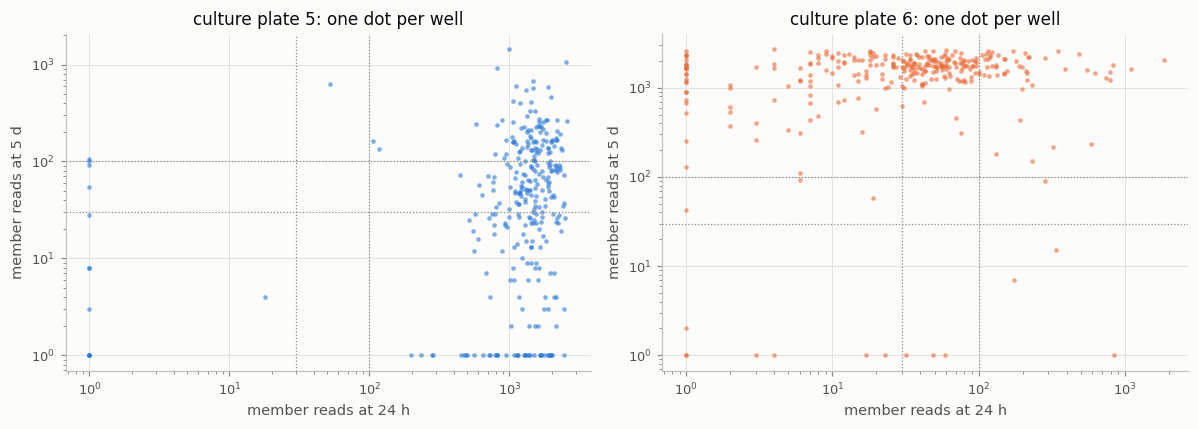

In [2]:
wells = pm.drop_duplicates(["culture_plate", "well"])[["culture_plate", "well", "member_reads_0", "member_reads_1", "size"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, (cp, g) in enumerate(wells.groupby("culture_plate")):
    ax[k].scatter(g.member_reads_0.clip(lower=1), g.member_reads_1.clip(lower=1), s=9, color=P.CAT[k], alpha=.6, lw=0)
    ax[k].set(xscale="log", yscale="log", xlabel="member reads at 24 h", ylabel="member reads at 5 d",
              title=f"culture plate {cp}: one dot per well")
    for v in (30, 100):
        ax[k].axvline(v, color=P.MUTED, lw=.8, ls=":"); ax[k].axhline(v, color=P.MUTED, lw=.8, ls=":")
fig.tight_layout(); savefig(fig, "03_coverage.png")
tab = []
for thr in (10, 30, 100, 300):
    for cp, g in wells.groupby("culture_plate"):
        tab.append(dict(min_member_reads_both=thr, culture_plate=cp,
                        wells=int(((g.member_reads_0 >= thr) & (g.member_reads_1 >= thr)).sum()),
                        of=len(g)))
pd.DataFrame(tab).pivot(index="min_member_reads_both", columns="culture_plate", values="wells")

What ~100 reads can and cannot resolve: a member at share *p* is seen with sampling SD
√(p(1−p)/n). At n = 100 that is ±4.4 points at p = 0.3 and ±1 point at p = 0.01, and a
1 % member is missed entirely 37 % of the time. So the shallow side resolves the
**dominant members and their rough proportions**, not the rare tail. Presence/absence
of 1 % members is only scored where the side being scored is deep.

In [3]:
n = np.array([30, 100, 300, 1000, 2000])
for p in (0.01, 0.05, 0.3):
    print(f"p={p:<5} SD of observed share: " + "  ".join(f"n={k}: ±{np.sqrt(p*(1-p)/k):.3f}" for k in n)
          + f"   P(miss) at n=100: {(1-p)**100:.2f}")

p=0.01  SD of observed share: n=30: ±0.018  n=100: ±0.010  n=300: ±0.006  n=1000: ±0.003  n=2000: ±0.002   P(miss) at n=100: 0.37
p=0.05  SD of observed share: n=30: ±0.040  n=100: ±0.022  n=300: ±0.013  n=1000: ±0.007  n=2000: ±0.005   P(miss) at n=100: 0.01
p=0.3   SD of observed share: n=30: ±0.084  n=100: ±0.046  n=300: ±0.026  n=1000: ±0.014  n=2000: ±0.010   P(miss) at n=100: 0.00


## 2. What happens between 24 h and 5 d

paired wells used: 359


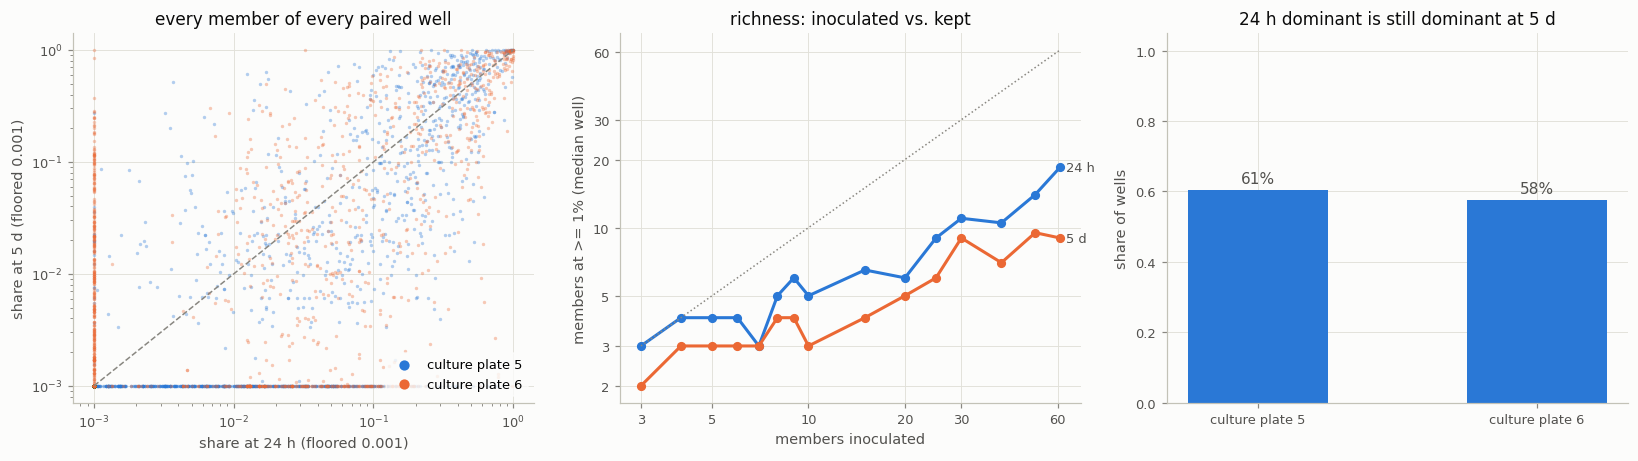

In [4]:
d0 = pm[(pm.member_reads_0 >= 30) & (pm.member_reads_1 >= 30)].copy()
d0["p0"] = d0.reads_0 / d0.member_reads_0; d0["p1"] = d0.reads_1 / d0.member_reads_1
rich = d0.groupby(["culture_plate", "well", "size"]).agg(r0=("p0", lambda x: (x >= .01).sum()),
                                                       r1=("p1", lambda x: (x >= .01).sum())).reset_index()
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for k, (cp, g) in enumerate(d0.groupby("culture_plate")):
    ax[0].scatter(g.p0.clip(lower=1e-3), g.p1.clip(lower=1e-3), s=5, alpha=.35, color=P.CAT[k], lw=0,
                  label=f"culture plate {cp}")
ax[0].plot([1e-3, 1], [1e-3, 1], color=P.MUTED, lw=1, ls="--")
ax[0].set(xscale="log", yscale="log", xlabel="share at 24 h (floored 0.001)", ylabel="share at 5 d (floored 0.001)",
          title="every member of every paired well")
lg = ax[0].legend(loc="lower right", markerscale=3, frameon=True, facecolor=P.SURFACE, edgecolor=P.SURFACE)
for h_ in lg.legend_handles:
    h_.set_alpha(1)
s = rich.groupby("size")[["r0", "r1"]].median()
ax[1].plot(s.index, s.r0, marker="o", color=P.CAT[0]); P.label_end(ax[1], s.index[-1], s.r0.iat[-1], "24 h")
ax[1].plot(s.index, s.r1, marker="o", color=P.CAT[1]); P.label_end(ax[1], s.index[-1], s.r1.iat[-1], "5 d")
ax[1].plot(s.index, s.index, color=P.MUTED, lw=1, ls=":")
ax[1].set(xscale="log", yscale="log", xlabel="members inoculated", ylabel="members at >= 1% (median well)",
          title="richness: inoculated vs. kept")
from matplotlib.ticker import FixedLocator, ScalarFormatter
for a_ in (ax[1].xaxis, ax[1].yaxis):
    a_.set_major_locator(FixedLocator([1, 2, 3, 5, 10, 20, 30, 60])); a_.set_major_formatter(ScalarFormatter())
    a_.set_minor_locator(FixedLocator([]))
dom = d0.loc[d0.groupby(["culture_plate", "well"]).p0.idxmax()][["culture_plate", "well", "strain"]]
dom1 = d0.loc[d0.groupby(["culture_plate", "well"]).p1.idxmax()][["culture_plate", "well", "strain"]]
dd = dom.merge(dom1, on=["culture_plate", "well"], suffixes=("_24h", "_5d"))
same = (dd.strain_24h == dd.strain_5d).groupby(dd.culture_plate).mean()
ax[2].bar([f"culture plate {c}" for c in same.index], same.values, color=P.CAT[0], width=.5)
for i, v in enumerate(same.values):
    ax[2].text(i, v + .02, f"{v:.0%}", ha="center", color=P.INK2)
ax[2].set(ylim=(0, 1.05), ylabel="share of wells", title="24 h dominant is still dominant at 5 d")
fig.tight_layout(); savefig(fig, "03_24h_vs_5d.png")
print(f"paired wells used: {d0[['culture_plate','well']].drop_duplicates().shape[0]}")

## 3. Leave-community-out models

In [5]:
d, gam = pred.cross_validate(pm, n_folds=10, min_reads_0=30, min_reads_1=30)
sc = pred.score_wells(d)
print(f"gamma (24 h log-abundance carried to 5 d) per fold: median {gam.gamma.median():.2f} "
      f"[{gam.gamma.min():.2f}-{gam.gamma.max():.2f}]")
order = ["persistence", "strain", "x_strain", "sister24_strain", "sister_ceiling"]
names = {"persistence": "persistence", "strain": "strain only", "x_strain": "24 h + strain",
         "sister24_strain": "sister 24 h + strain", "sister_ceiling": "sister 5 d (ceiling)"}
summ = (sc.groupby(["model", "culture_plate"])
          .agg(wells=("wid", "size"), bray_curtis=("bray_curtis", "median"), spearman=("spearman", "median"),
               dominant_correct=("dominant_correct", "mean"), noise_floor_bc=("noise_floor_bc", "median"))
          .reindex(order, level=0).round(3))
summ

gamma (24 h log-abundance carried to 5 d) per fold: median 0.34 [0.31-0.36]


wells  bray_curtis  spearman  dominant_correct  noise_floor_bc
model           culture_plate                                                                
persistence     5                180        0.323     0.771             0.606           0.041
                6                179        0.314     0.656             0.575           0.012
strain          5                180        0.333     0.773             0.633           0.041
                6                179        0.244     0.786             0.704           0.012
x_strain        5                180        0.303     0.785             0.661           0.041
                6                179        0.216     0.778             0.709           0.012
sister24_strain 5                161        0.299     0.778             0.665           0.041
                6                157        0.205     0.800             0.739           0.012
sister_ceiling  5                161        0.110     0.885             0.839           0.041
                6                157        0.101     0.945             0.885           0.012

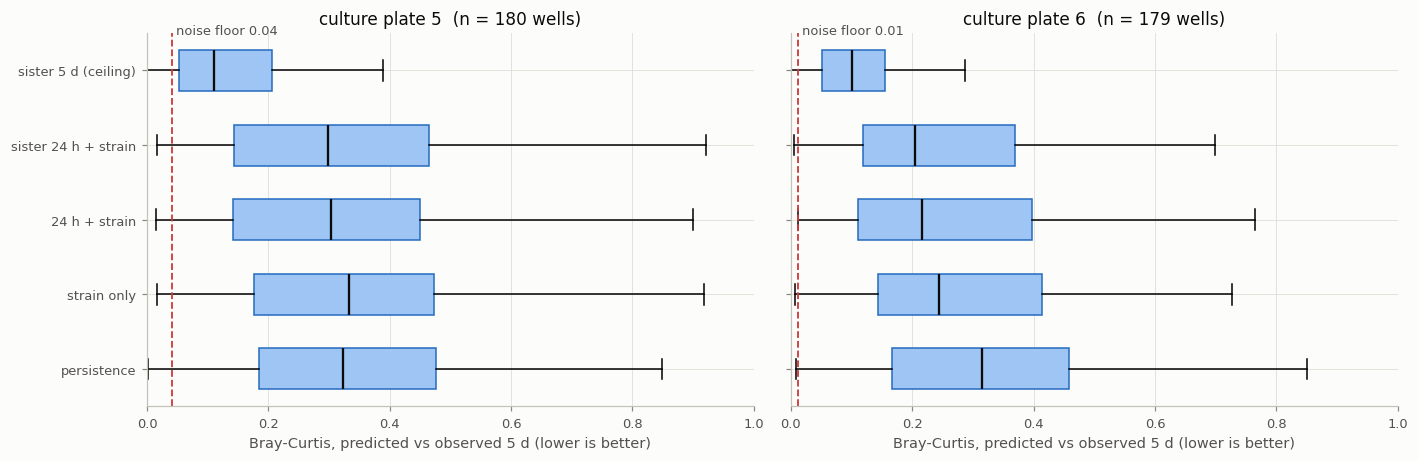

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for k, (cp, g) in enumerate(sc.groupby("culture_plate")):
    data = [g[g.model == m].bray_curtis.to_numpy() for m in order]
    bp = ax[k].boxplot(data, vert=False, widths=.55, patch_artist=True, showfliers=False,
                       medianprops=dict(color=P.INK, lw=1.5))
    for b in bp["boxes"]:
        b.set(facecolor=P.SEQ_STEPS[1], edgecolor=P.SEQ_STEPS[4], lw=1)
    fl = g.drop_duplicates("wid").noise_floor_bc.median()
    ax[k].axvline(fl, color=P.STATUS["critical"], lw=1.2, ls="--")
    ax[k].text(fl, len(order) + .45, f" noise floor {fl:.2f}", color=P.INK2, fontsize=8.5, va="bottom")
    ax[k].set(yticks=range(1, len(order) + 1), yticklabels=[names[m] for m in order], xlim=(0, 1),
              xlabel="Bray-Curtis, predicted vs observed 5 d (lower is better)",
              title=f"culture plate {cp}  (n = {g.wid.nunique()} wells)")
    ax[k].invert_yaxis()
fig.tight_layout(); savefig(fig, "03_model_scores.png")

In [7]:
auc = pred.survival_auc(d[d.reads_1 >= 0])
deep = d[d.culture_plate == 6]   # 5 d side deep -> presence at 1% is well measured
auc6 = pred.survival_auc(deep).assign(subset="culture plate 6 (5 d deep)")
pd.concat([auc.assign(subset="all paired wells"), auc6]).round(3)

,model,auc,n,share_surviving,subset
0,persistence,0.844,3248,0.392,all paired wells
1,strain,0.871,3248,0.392,all paired wells
2,x_strain,0.889,3248,0.392,all paired wells
3,sister24_strain,0.895,2971,0.389,all paired wells
4,sister_ceiling,0.946,2971,0.389,all paired wells
0,persistence,0.808,1587,0.423,culture plate 6 (5 d deep)
1,strain,0.869,1587,0.423,culture plate 6 (5 d deep)
2,x_strain,0.877,1587,0.423,culture plate 6 (5 d deep)
3,sister24_strain,0.890,1438,0.425,culture plate 6 (5 d deep)
4,sister_ceiling,0.973,1438,0.425,culture plate 6 (5 d deep)


## 4. Own 24 h vs. the sister replicates' 24 h

318 wells; median BC own 24 h 0.254 vs sister 24 h 0.255; own better in 51% of wells; Wilcoxon p = 0.89


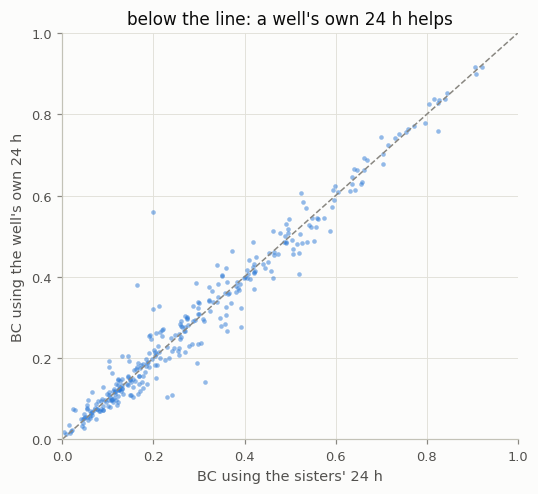

In [8]:
a = sc[sc.model == "x_strain"].set_index("wid").bray_curtis
b = sc[sc.model == "sister24_strain"].set_index("wid").bray_curtis
j = pd.concat([a.rename("own"), b.rename("sister")], axis=1).dropna()
from scipy import stats
w = stats.wilcoxon(j.own, j.sister)
print(f"{len(j)} wells; median BC own 24 h {j.own.median():.3f} vs sister 24 h {j.sister.median():.3f}; "
      f"own better in {(j.own < j.sister).mean():.0%} of wells; Wilcoxon p = {w.pvalue:.2g}")
fig, ax = plt.subplots(figsize=(5, 4.6))
ax.scatter(j.sister, j.own, s=9, alpha=.5, color=P.CAT[0], lw=0)
ax.plot([0, 1], [0, 1], color=P.MUTED, ls="--", lw=1)
ax.set(xlabel="BC using the sisters' 24 h", ylabel="BC using the well's own 24 h", xlim=(0, 1), ylim=(0, 1),
       title="below the line: a well's own 24 h helps")
fig.tight_layout(); savefig(fig, "03_own_vs_sister.png")

## 5. Strain effects: who gains and who loses between 24 h and 5 d

gamma on all data = 0.33; 75 strains in >= 5 paired wells


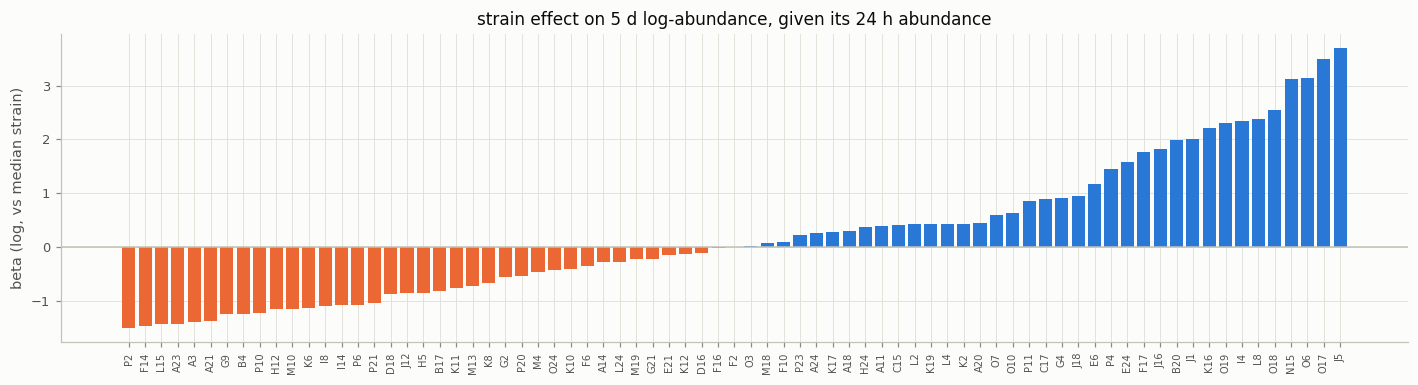

In [9]:
strains = sorted(d.strain.unique())
Dc = pred._design(d, strains)
g_all, b_all = pred._fit(d.x.to_numpy(), d.y.to_numpy(), Dc, use_x=True, ridge=1.0)
n_w = d.groupby("strain").wid.nunique()
beta = pd.DataFrame({"strain": strains, "beta": b_all - np.median(b_all)}).assign(wells=lambda t: t.strain.map(n_w))
beta = beta[beta.wells >= 5].sort_values("beta")
print(f"gamma on all data = {g_all:.2f}; {len(beta)} strains in >= 5 paired wells")
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(range(len(beta)), beta.beta, color=np.where(beta.beta > 0, P.CAT[0], P.CAT[1]), width=.8)
ax.set_xticks(range(len(beta)), beta.strain, rotation=90, fontsize=6.5)
ax.axhline(0, color=P.AXIS, lw=1)
ax.set(ylabel="beta (log, vs median strain)", title="strain effect on 5 d log-abundance, given its 24 h abundance")
fig.tight_layout(); savefig(fig, "03_strain_effects.png")